In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image
from matplotlib.figure import Figure
from matplotlib.offsetbox import OffsetImage, AnnotationBbox


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *


cm = 1/2.54  # centimeters in inches
import matplotlib as mpl


fixed_factor = 0.8 #Origin fixed factor for police size
figsize_conversion_coeff =  1.381 # To have matching graph size with origin
mpl.rcParams["font.size"] = 20*fixed_factor
mpl.rcParams['axes.linewidth'] = 1.5 #graph border lines width
mpl.rcParams['font.family'] = 'Arial'

dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Conference\2026-07 - META\slides\Figures'
saving_figures = False

## Figure 1 : sample presentation

## All PaP signals together : Nd on Sapphire studied in 2025

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\Octobre 2024'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic


580 -147944.46037545914
590 -159567.24705257438
720 -209896.89086247204
660 -186962.58575057233
640 -184587.61252134998
700 -203933.99845391957
710 -208225.71113093922
650 -188219.37519454
670 -186999.9016906599
680 -189030.03162651492
690 -200513.55149086233
600 -164212.02184506867
610 -169716.30234597126
620 -181158.69367665632
630 -180981.23070935957


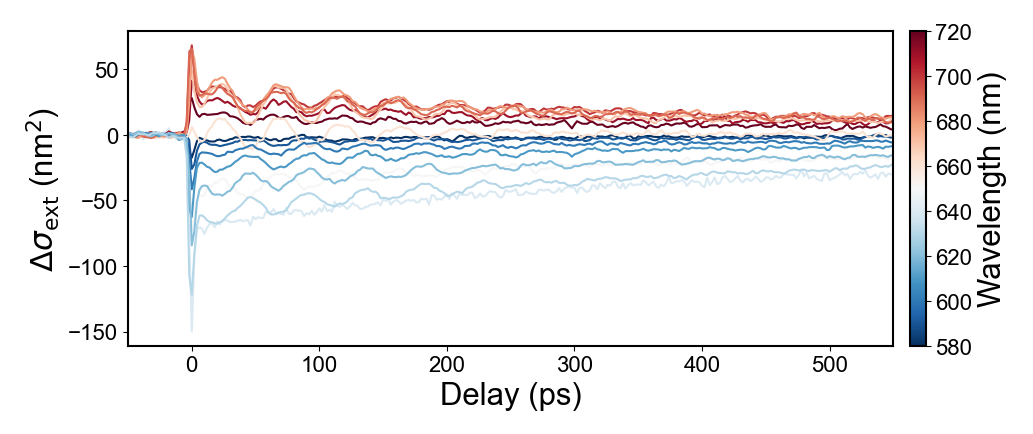

In [3]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
cmap = plt.get_cmap('copper')
cmap = plt.get_cmap('RdBu')
cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff,
        color=cmap(norm(trace.lda_probe))
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Wavelength (nm)', fontsize=28*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=28*fixed_factor)
ax.set_ylabel(r'$\Delta \sigma_{\mathrm{ext}}$ (nm$^2$)', fontsize=28*fixed_factor)
ax.set_xlim( (-50, 550))


fig.set_size_inches((19*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - NDe thick sapphire.svg')
    plt.savefig('All raw PaP signals - NDe thick sapphire.png')

## All PaP signals together : ND2 zone1 on thick Silica studied in April 2026

In [5]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-04'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_1D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic


640 -189513.15978932692
650 -196829.84188182733
590 -160188.77820316196
600 -163234.95725088243
610 -169090.4338772601
620 -171889.46652642364
580 -148577.27034522264
660 -207673.35496430311
670 -208145.3577734657
680 -207869.9899299711
690 -205655.44258301528
570 -143376.74634141297
630 -179771.5691192893
700 -205966.69726811253


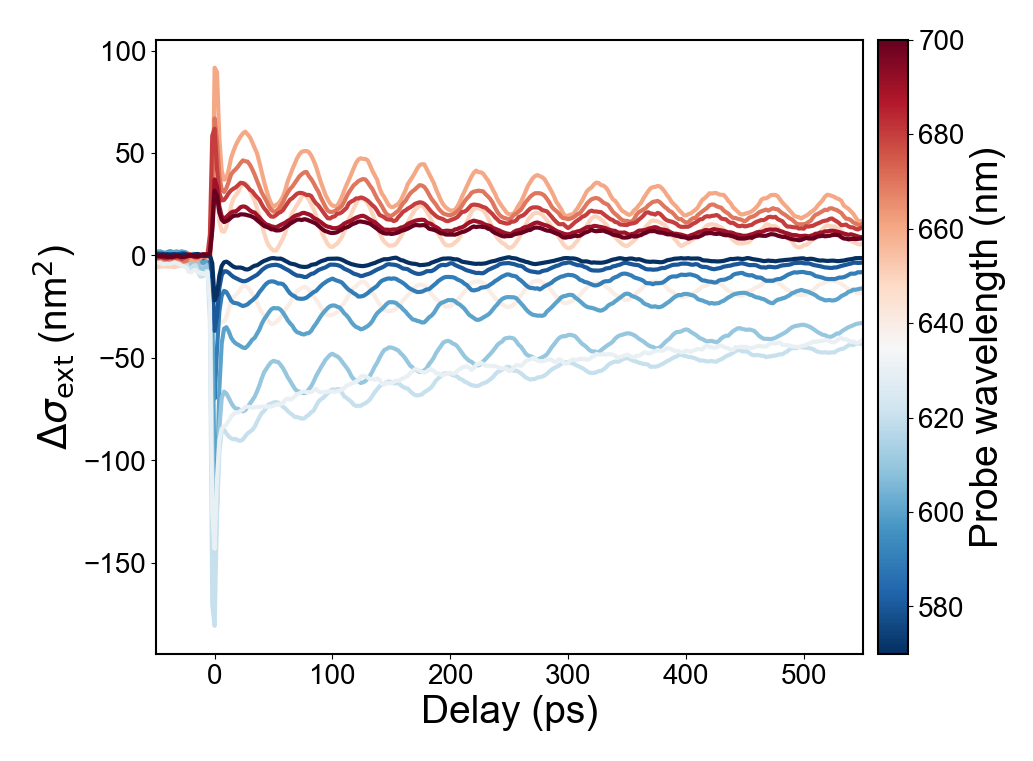

In [8]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 7*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
cmap = plt.get_cmap('copper')
cmap = plt.get_cmap('RdBu')
cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff,
        color=cmap(norm(trace.lda_probe)), linewidth=3
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Probe wavelength (nm)', fontsize=35*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=35*fixed_factor)
ax.set_ylabel(r'$\Delta \sigma_{\mathrm{ext}}$ (nm$^2$)', fontsize=35*fixed_factor)
ax.set_xlim((-50, 550))



fig.set_size_inches((19*cm*figsize_conversion_coeff, 14*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if 1 :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.svg')
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.png')

## PaP acoustic component

In [3]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'16-Apr-2026_PaP_Pp10uW_ldap410nm_ldas_650'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

C:\Users\nberr\AppData\Local\Temp\ipykernel_19460\4092001154.py:53: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_19460\4092001154.py:53: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_19460\4092001154.py:54: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_19460\4092001154.py:54: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



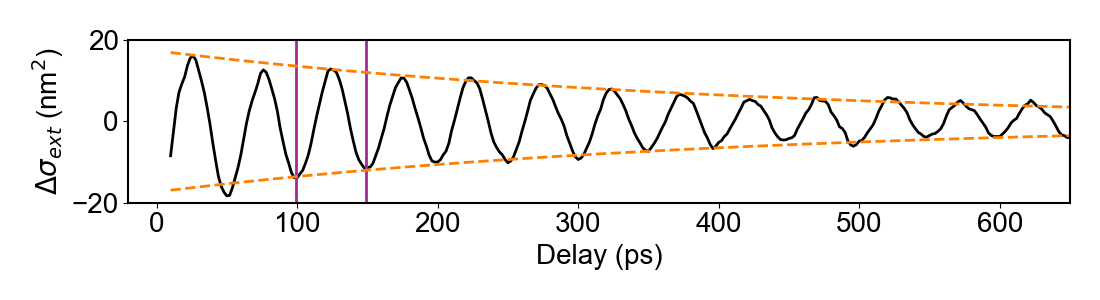

In [4]:
mpl.rcParams["font.size"] = 20
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -215347.14701364425 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,3))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black', linewidth=2)


#ax.plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label='fit', linewidth=2)



ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')

xlim = (-20, 650)
ylim = (-20, 20)

ax.set_xlim(xlim)
ax.set_ylim(ylim)
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
#plt.legend(fontsize=20)
plt.tight_layout()

if 1 :
    os.chdir(dir_save_data)
    plt.savefig('PaP acoustic component - 1.svg')
    plt.savefig('PaP acoustic component - 1.png')

color="#A02B93"
ax.axvline(99, color=color,linewidth=2)
ax.axvline(149,color=color, linewidth=2)


ax.set_xlim(xlim)
ax.set_ylim(ylim)
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
#plt.legend(fontsize=20)
plt.tight_layout()

if 1 :
    os.chdir(dir_save_data)
    plt.savefig('PaP acoustic component - 2.svg')
    plt.savefig('PaP acoustic component - 2.png')


color="#FF8000"
ax.plot(Trace.delay, Trace.acoustic_fit['1 modes']['coeffs'][0]*alpha_DTT_dsigma * np.exp(-Trace.delay/Trace.acoustic_fit['1 modes']['coeffs'][1]) , 'r-', color= color, linestyle='--',label='fit', linewidth=2)
ax.plot(Trace.delay, -Trace.acoustic_fit['1 modes']['coeffs'][0]*alpha_DTT_dsigma * np.exp(-Trace.delay/Trace.acoustic_fit['1 modes']['coeffs'][1]) , 'r-', color= color, linestyle='--',label='fit', linewidth=2)


ax.set_xlim(xlim)
ax.set_ylim(ylim)
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
#plt.legend(fontsize=20)
plt.tight_layout()

if 1 :
    os.chdir(dir_save_data)
    plt.savefig('PaP acoustic component - 3.svg')
    plt.savefig('PaP acoustic component - 3.png')


## PaP gif

In [6]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Acoustic study - second mode detection\NDd zone 3\-1300ps to 0 ps'
dir_name = r'2025-12-19_PaP_Pp20uW_ldap410nm_ldas660nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

alpha_DTT_dsigma = -172035.5417065772 #conversion coefficient from DTT to delta sigma in nm2
# ax.plot(Trace.delay_tot[10:], (Trace.DTT_tot[10:] - Trace.mean_start)*alpha_DTT_dsigma,  color = 'black')


180


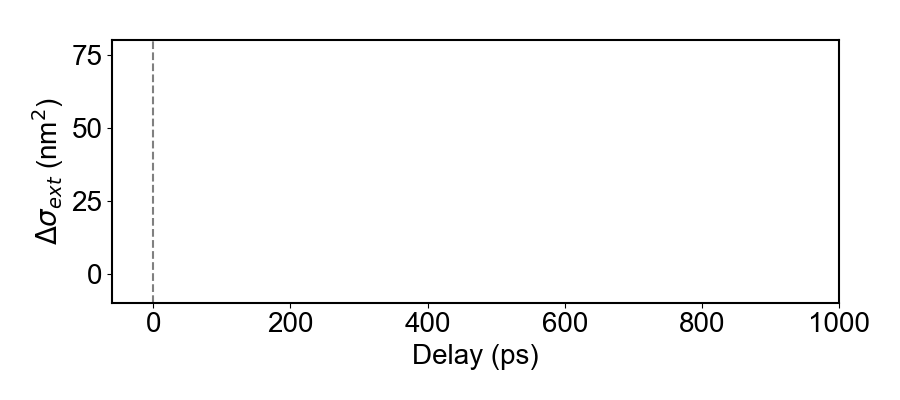

In [7]:
animation_name = 'PaP measurements'

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))


imax=250
imax = 180
Time = Trace.delay_tot[10:]
n_time = np.size(Time)

Sigma = (Trace.DTT_tot[10:] - Trace.mean_start)*alpha_DTT_dsigma

ax.set_ylim((-10, 80))
ax.set_xlim((-60, 1000))

ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()
ax.axvline(0, linestyle = '--', color = 'grey')

x = np.linspace(0, 10, 1000)
x =range(0, imax)
print(len(x))




def animate_dtt(i) :
    
    index = int(i*(n_time-1)/imax) 
    ax.cla()
    ax.set_ylim((-10, 80))
    ax.set_xlim((-60, 1000))
    mpl.rcParams["font.size"] = 20
    ax.axvline(0, linestyle = '--', color = 'grey')
    ax.axvline(Time[index-1], linestyle = '--', color = 'grey')

    arr_img = plt.imread("beam_impulsion.png")


    # Position et zoom
    x_data, y_data = Time[index-1], 50
    zoom = 0.3

    # Convertir la position data -> pixels
    x_px, y_px = ax.transData.transform((x_data, y_data))

    # Dimensions de l'image après zoom
    img_h, img_w = arr_img.shape[:2]
    img_w_zoomed = int(img_w * zoom)
    img_h_zoomed = int(img_h * zoom)

    # Limites des axes en pixels
    ax_x0, ax_y0, ax_x1, ax_y1 = ax.bbox.extents
    print(ax_x1)
    # Calcul de la partie visible (rogner à droite et en haut)
    visible_w = int(min(img_w, (ax_x1-20 - x_px) / zoom))
    visible_h = int(min(img_h, (y_px - ax_y0) / zoom))
    if visible_w >0 and visible_h >0:
        # Rogner le tableau numpy
        arr_cropped = arr_img[:visible_h, :visible_w]

        im = OffsetImage(arr_cropped, zoom=zoom)
        ab = AnnotationBbox(im, (x_data, y_data), xycoords='data', frameon=False,
                            box_alignment=(0, 0))
        ax.add_artist(ab)

        ax.text(x_data+5, y_data - 7, 'probe')


    # Position et zoom
    x_data, y_data = 0, 65
    zoom = 0.3

    # Convertir la position data -> pixels
    x_px, y_px = ax.transData.transform((x_data, y_data))

    # Dimensions de l'image après zoom
    img_h, img_w = arr_img.shape[:2]
    img_w_zoomed = int(img_w * zoom)
    img_h_zoomed = int(img_h * zoom)

    # Limites des axes en pixels
    ax_x0, ax_y0, ax_x1, ax_y1 = ax.bbox.extents
    print(ax_x1)
    # Calcul de la partie visible (rogner à droite et en haut)
    visible_w = int(min(img_w, (ax_x1-20 - x_px) / zoom))
    visible_h = int(min(img_h, (y_px - ax_y0) / zoom))
    if visible_w >0 and visible_h >0:
        # Rogner le tableau numpy
        arr_cropped = arr_img[:visible_h, :visible_w]

        im = OffsetImage(arr_cropped, zoom=zoom)
        ab = AnnotationBbox(im, (x_data, y_data), xycoords='data', frameon=False,
                            box_alignment=(0, 0))
        ax.add_artist(ab)

        ax.text(x_data+5, y_data - 7, 'pump')




    ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
    ax.set_xlabel('Delay (ps)')
    #ax.grid('on')
    fig.patch.set_facecolor( '#FF000000' )
    plt.tight_layout()

    scat = ax.plot(Time[:index], Sigma[:index], color='black')

    return(scat,)



#interval=1000//60
ani_dtt = animation.FuncAnimation(fig, animate_dtt, repeat=True, frames=imax, interval = 500)
plt.show()





if saving_figures :
    os.chdir(dir_save_data)
        
    # writer = animation.PillowWriter(fps=15,
    #                                 metadata=dict(artist='Me'),
    #                                 bitrate=1800)
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani_dtt.save(animation_name + '-2.gif', writer=writer)

plt.clf()

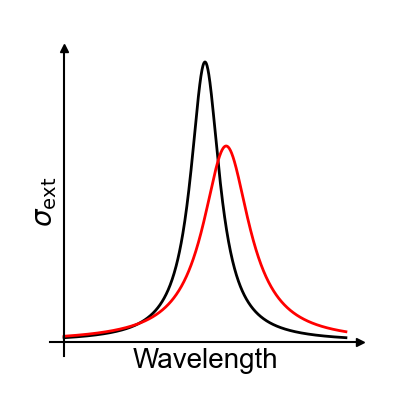

In [8]:
fig, ax = plt.subplots(figsize = (4,4))


ax.spines["left"].set_position(("data", 0))
ax.spines["bottom"].set_position(("data", 0))
ax.plot(1, 0, ">k", transform=ax.get_yaxis_transform(), clip_on=False)
ax.plot(0, 1, "^k", transform=ax.get_xaxis_transform(), clip_on=False)



Energy = np.linspace(0, 0.4, 1000)
plt.plot(Energy, Lorentz_no_offset(Energy, A =100, w=0.05, xc=0.2), linewidth = 2, color='black')
plt.plot(Energy, Lorentz_no_offset(Energy, A =70, w=0.08, xc=0.23), linewidth = 2, color='red')


ax.set_xticks([])
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel(r'Wavelength')
ax.set_ylabel(r'$\sigma_{\mathrm{ext}}$')


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('SPR - simple presentation.svg')
    plt.savefig('SPR - simple presentation.png')


## Animation of shape variation

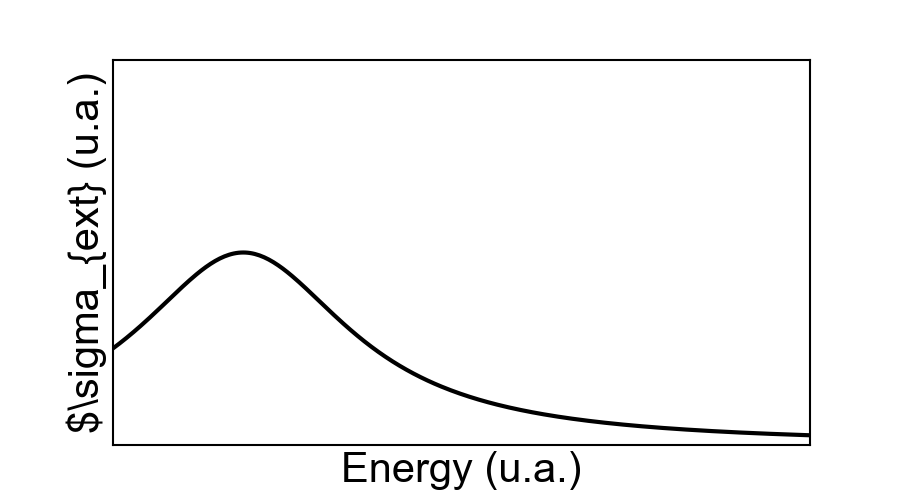

In [9]:
animation_name = 'Intermediate geometry - v1'

mpl.rcParams["font.size"] = 30

fig, ax = plt.subplots(figsize=(9,5))


imax=100

#Set (x,y) limits for axes
xmin_spr, xmax_spr = (2,  10)

ymin_spr, ymax_spr = (0,  20)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -0.7, 0.7


AR = np.linspace(xmin_spr, xmax_spr, 300)



def f1_AR(AR) :
    return(Lorentz_no_offset(AR, 3.5, 3, 10))

def f2_AR(AR) :
    return (Lorentz_no_offset(AR, 8.5, 3, 10))






ax.set_xlim((xmin_spr, xmax_spr))
ax.set_ylim((ymin_spr, ymax_spr))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('Energy (u.a.)')
ax.set_ylabel(r'$\sigma_{ext} (u.a.)')




scat = ax.plot(AR, f1_AR(AR),color='black', linewidth=3)





def animate_lorentz(i) :
    ax.cla()
    #x_probe = Energy[600]


    ### SPR plot 
    ax.set_xlim((xmin_spr, xmax_spr))
    ax.set_ylim((ymin_spr, ymax_spr))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('AR ')
    ax.set_ylabel(r'Q$_\mathrm{rad}$')

    width, height = 0.1, 0.07
    x_ini, y_ini = 0.13 , 0.8

    x_f, y_f = 0.7 , 0.55 

    r =  i/imax*height/2



    x_c_ini, y_c_ini = x_ini , y_ini 


    x_c, y_c = x_ini +(x_f-x_ini)*i/imax , y_ini +(y_f-y_ini)*i/imax 

    ## Cylindrical ND
    rect_disk = mpatches.Rectangle((x_c_ini, y_c_ini), width, height, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk)   



    ## Modified ND
    rect_disk = mpatches.Rectangle((x_c, y_c+r), width, height-2*r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk)

    rect_disk_2 = mpatches.Rectangle((x_c+r, y_c), width-2*r, height, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk_2)

    circle = mpatches.Circle((x_c+r, y_c+r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle)

    circle_2 = mpatches.Circle((x_c+ width -r, y_c+r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_2)

    circle_3 = mpatches.Circle((x_c + r, y_c + height - r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_3)

    circle_4 = mpatches.Circle((x_c + width - r, y_c + height - r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_4)



    
    ## Final ND
    rect_disk = mpatches.Rectangle((x_f, y_f+height/2), width, height-2*height/2, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk)

    rect_disk_2 = mpatches.Rectangle((x_f+height/2, y_f), width-2*height/2, height, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk_2)

    circle = mpatches.Circle((x_f+height/2, y_f+height/2), height/2, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle)

    circle_2 = mpatches.Circle((x_f+ width -height/2, y_f+height/2), height/2, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_2)

    circle_3 = mpatches.Circle((x_f + height/2, y_f + height - height/2), height/2, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_3)

    circle_4 = mpatches.Circle((x_f + width - height/2, y_f + height - height/2), height/2, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_4)

    scat = ax.plot(AR, Lorentz_no_offset(AR, 3.5  + i/imax*(8-3.5), 1 + i/imax*(3-1) , 15 + i/imax*(10-15)) ,color='grey', linewidth=3)

    scat = ax.plot(AR, Lorentz_no_offset(AR, 3.5  , 1 , 15 ) ,color='black', linewidth=3)
    scat = ax.plot(AR, Lorentz_no_offset(AR, 8,3 , 10) ,color='red', linewidth=3)
    #ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    #ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

   
    #ax.axvline(x_probe, color='green', linestyle='--',zorder=0)
    #ax.text(0.63, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax.transAxes)




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  0 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

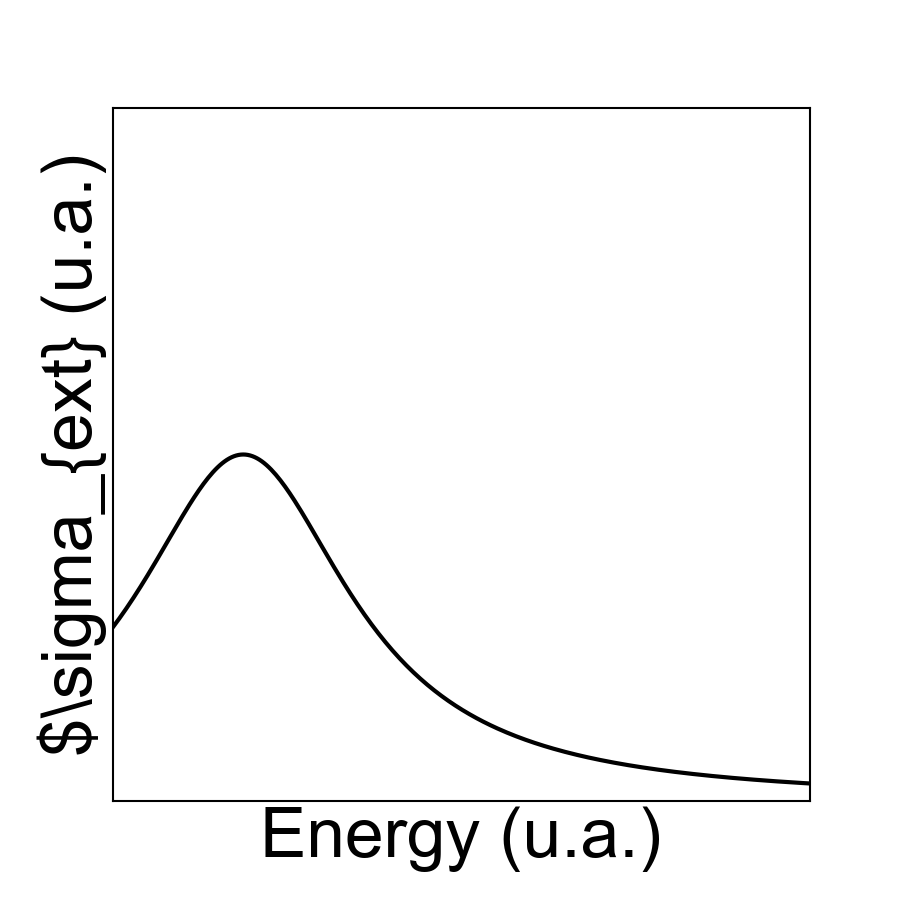

In [4]:
animation_name = 'Intermediate geometry - v2'

mpl.rcParams["font.size"] = 50

fig, ax = plt.subplots(figsize=(9,9))


imax=100

#Set (x,y) limits for axes
xmin_spr, xmax_spr = (2,  10)
ymin_spr, ymax_spr = (0,  20)




AR = np.linspace(xmin_spr, xmax_spr, 300)



def f1_AR(AR) :
    return(Lorentz_no_offset(AR, 3.5, 3, 10))

def f2_AR(AR) :
    return (Lorentz_no_offset(AR, 8.5, 3, 10))




ax.set_xlim((xmin_spr, xmax_spr))
ax.set_ylim((ymin_spr, ymax_spr))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('Energy (u.a.)')
ax.set_ylabel(r'$\sigma_{ext} (u.a.)')


scat = ax.plot(AR, f1_AR(AR),color='black', linewidth=3)



def animate_lorentz(i) :
    ax.cla()
    #x_probe = Energy[600]


    ### SPR plot 
    ax.set_xlim((xmin_spr, xmax_spr))
    ax.set_ylim((ymin_spr, ymax_spr))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('AR ')
    ax.set_ylabel(r'Q$_\mathrm{rad}$')

    width, height = 0.1*3, 0.035*3
    x_ini, y_ini = 0.6 , 0.8


    r =  i/imax*height/2



    x_c,y_c = x_ini , y_ini 

    # Cursor coordinates

    x_min_cursor = x_c 
    x_max_cursor = x_c + width
    x_cursor = x_min_cursor + i/imax * (x_max_cursor - x_min_cursor)

    ## Modified ND
    rect_disk = mpatches.Rectangle((x_c, y_c+r), width, height-2*r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk)

    rect_disk_2 = mpatches.Rectangle((x_c+r, y_c), width-2*r, height, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(rect_disk_2)

    circle = mpatches.Circle((x_c+r, y_c+r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle)

    circle_2 = mpatches.Circle((x_c+ width -r, y_c+r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_2)

    circle_3 = mpatches.Circle((x_c + r, y_c + height - r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_3)

    circle_4 = mpatches.Circle((x_c + width - r, y_c + height - r), r, transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='none')
    ax.add_patch(circle_4)


    # ## Draw the border of ND.

    def quarter_arc(cx, cy, r, theta_start_deg, theta_end_deg, n=50):
        theta = np.linspace(np.radians(theta_start_deg), np.radians(theta_end_deg), n)
        return cx + r*np.cos(theta), cy + r*np.sin(theta)

    xs_all, ys_all = [], []

    # Coin bas-gauche
    xa, ya = quarter_arc(x_c+r, y_c+r, r, 180, 270)
    xs_all.append(xa); ys_all.append(ya)

    # Bas
    xs_all.append(np.array([x_c+r, x_c+width-r])); ys_all.append(np.array([y_c, y_c]))

    # Coin bas-droit
    xa, ya = quarter_arc(x_c+width-r, y_c+r, r, 270, 360)
    xs_all.append(xa); ys_all.append(ya)

    # Droite
    xs_all.append(np.array([x_c+width, x_c+width])); ys_all.append(np.array([y_c+r, y_c+height-r]))

    # Coin haut-droit
    xa, ya = quarter_arc(x_c+width-r, y_c+height-r, r, 0, 90)
    xs_all.append(xa); ys_all.append(ya)

    # Haut
    xs_all.append(np.array([x_c+width-r, x_c+r])); ys_all.append(np.array([y_c+height, y_c+height]))

    # Coin haut-gauche
    xa, ya = quarter_arc(x_c+r, y_c+height-r, r, 90, 180)
    xs_all.append(xa); ys_all.append(ya)

    # Gauche
    xs_all.append(np.array([x_c, x_c])); ys_all.append(np.array([y_c+height-r, y_c+r]))

    xs_all = np.concatenate(xs_all)
    ys_all = np.concatenate(ys_all)

    ax.plot(xs_all, ys_all, transform=ax.transAxes, color="#000000ff",
            linewidth=2, solid_joinstyle='round', solid_capstyle='round')
    scat = ax.plot(AR, Lorentz_no_offset(AR, 3.5  + i/imax*(8-3.5), 1 + i/imax*(3-1) , 15 + i/imax*(10-15)) ,color='grey', linewidth=3)



    # ## Cursor variation

    circle = mpatches.Circle((x_cursor, y_c-0.4*height), 0.015, transform=ax.transAxes, facecolor="#000000ff", edgecolor='none')
    ax.add_patch(circle)

    scat = ax.plot([x_min_cursor, x_max_cursor], [y_c- 0.4*height, y_c - 0.4*height], transform=ax.transAxes,color="#000000ff", linewidth=3)

    ax.text(x_c + width/2, y_c-height*1, 'edge curvature', transform=ax.transAxes, horizontalalignment = 'center', fontsize=30)



    #ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    #ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

   
    #ax.axvline(x_probe, color='green', linestyle='--',zorder=0)
    #ax.text(0.63, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax.transAxes)




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18